 RevDE: reversible differential evolution

`RevDE` turns three parent vectors into three children with one fixed 3x3 matrix built from a scaling factor. Because the matrix can be inverted, no information is lost: the parents can be recovered from the children. It lives in `seachange.optimizers.revde` and works on float64 numpy arrays.

This notebook prints the matrix, recovers three parents from their children, draws one parent and child triple in the plane, and then runs RevDE inside an `EA` to find the lowest point of a bowl-shaped function, drawing the population at three moments of the run.

In [1]:
# standard library
from pathlib import Path

In [2]:
# third-party
import matplotlib.pyplot as plt
import numpy as np
from numpy.typing import NDArray

In [3]:
# local
from seachange import EA, Archive, EAOperation, Individual, Population, seed
from seachange.optimizers.revde import RevDE

In [4]:
%matplotlib inline
plt.rcParams["figure.dpi"] = 72

type Point = NDArray[np.float64]

SEED = 2
rng = np.random.default_rng(SEED)
SCALING_FACTOR = -0.5
POPULATION_SIZE = 30
GENERATIONS = 30
SNAPSHOTS = (0, 5, GENERATIONS)
TARGET = np.array([1.0, -1.0])
TOLERANCE = 0.05
DATABASE = Path("__data__") / "revde.db"

seed(SEED)

# The matrix

Each child is a weighted sum of the three parents; row k of the matrix holds child k's weights. A non-zero determinant means the matrix has an inverse.

In [5]:
revde = RevDE(scaling_factor=SCALING_FACTOR)
print(revde.r_matrix)
determinant = np.linalg.det(revde.r_matrix)
print(f"determinant {determinant:.3f}")
assert abs(determinant) > TOLERANCE

[[ 1.    -0.5    0.5  ]
 [ 0.5    0.75  -0.25 ]
 [-0.25   0.625  0.625]]
determinant 1.000


# Children back to parents

Multiplying the children by the inverse matrix gives the parents back, to rounding error.

In [6]:
parents = [rng.uniform(-3, 3, size=2) for _ in range(3)]
children = revde.mutate(*parents)
recovered = np.linalg.inv(revde.r_matrix) @ np.vstack(children)
print("parents:  ", np.round(np.vstack(parents), 3).tolist())
print("recovered:", np.round(recovered, 3).tolist())
assert np.allclose(recovered, np.vstack(parents))

parents:   [[-1.43, -1.209], [1.885, -2.449], [0.601, 1.371]]
recovered: [[-1.43, -1.209], [1.885, -2.449], [0.601, 1.371]]


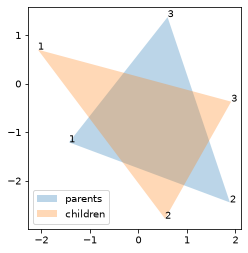

In [7]:
fig, ax = plt.subplots(figsize=(4, 4))
ax.fill(*np.vstack(parents).T, alpha=0.3, label="parents")
ax.fill(*np.vstack(children).T, alpha=0.3, label="children")
for k, (parent, child) in enumerate(zip(parents, children, strict=True)):
    ax.annotate(str(k + 1), (parent[0], parent[1]))
    ax.annotate(str(k + 1), (child[0], child[1]))
ax.set_aspect("equal")
ax.legend()
plt.show()

# RevDE in a run

Each individual is a point in the plane; its fitness is minus its squared distance to (1, -1), so higher is better and the best point is the target. Every generation the population is shuffled into triples, each triple makes three children with RevDE, and the best thirty of parents and children survive.

In [8]:
def new_individual(point: Point) -> Individual[Point]:
    """Return an unevaluated individual at ``point``.

    Returns
    -------
    Individual[Point]
        The individual.
    """
    individual: Individual[Point] = Individual()
    individual.genotype = point
    return individual


def evaluate(population: Population[Point]) -> Population[Point]:
    """Score each new point by minus its squared distance to the target.

    Returns
    -------
    Population[Point]
        The same population, every member evaluated.
    """
    for member in population.unevaluated:
        member.fitness = -float(np.sum((member.genotype - TARGET) ** 2))
    return population


def reproduce(population: Population[Point]) -> Population[Point]:
    """Add three RevDE children for every triple of shuffled parents.

    Returns
    -------
    Population[Point]
        The population with the children added.
    """
    shuffled = population.shuffle().to_list()
    for start in range(0, len(shuffled) - 2, 3):
        triple = [member.genotype for member in shuffled[start : start + 3]]
        for child in revde.mutate(*triple):
            population.append(new_individual(child))
    return population


def retire_worst(population: Population[Point]) -> Population[Point]:
    """Mark all but the best POPULATION_SIZE individuals as dead.

    Returns
    -------
    Population[Point]
        The same population; the dead stay in the database.
    """
    for member in population.sort()[POPULATION_SIZE:]:
        member.alive = False
    return population

In [9]:
first = Population([
    new_individual(rng.uniform(-4, 4, size=2)) for _ in range(POPULATION_SIZE)
])
with EA(
    evaluate(first),
    [EAOperation(reproduce), EAOperation(evaluate), EAOperation(retire_worst)],
    num_steps=GENERATIONS,
    db_file_path=DATABASE,
    quiet=True,
) as ea:
    ea.run()
    best = ea.get_solution("best")
print(
    "best point:", np.round(best.genotype, 4), " fitness", f"{best.fitness:.2e}"
)
assert np.allclose(best.genotype, TARGET, atol=TOLERANCE)

best point: [ 1. -1.]  fitness -1.77e-12


The survivors of generations 0, 5 and 30, read back from the database, over the bowl's contour lines. The population starts spread over the square and closes in on the cross at (1, -1).

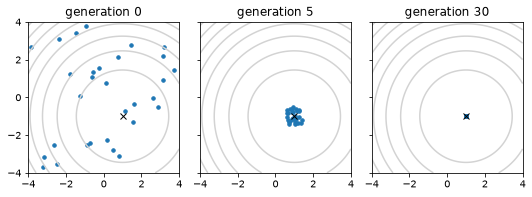

In [10]:
grid = np.linspace(-4, 4, 81)
xs, ys = np.meshgrid(grid, grid)
heights = (xs - TARGET[0]) ** 2 + (ys - TARGET[1]) ** 2
fig, axes = plt.subplots(1, len(SNAPSHOTS), figsize=(7.5, 2.7), sharey=True)
with Archive[Point](DATABASE) as archive:
    for ax, generation in zip(axes, SNAPSHOTS, strict=True):
        survivors = [
            m.genotype
            for m in archive.by_generation(generation)
            if m.alive or m.time_of_death > generation
        ]
        ax.contour(xs, ys, heights, levels=8, colors="lightgrey")
        ax.scatter(*np.vstack(survivors).T, s=12)
        ax.plot(*TARGET, marker="x", color="black")
        ax.set_title(f"generation {generation}")
        ax.set_aspect("equal")
fig.tight_layout()
plt.show()